In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/Ecommerce_cleaned (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (25000, 29)


,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,discount_percent,discount_amount,revenue,pages_viewed,time_on_site_sec,added_to_cart,purchased,cart_abandoned,rating,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,2024-11-28,2,1,2,894,6,651.57,1,20,130.31,0.00,21,965,1,0,1,4,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,2024-09-25,2,0,4,844,2,945.27,4,15,567.16,0.00,21,1158,0,0,0,4,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,2024-05-31,1,1,0,865,0,400.44,4,0,0.00,0.00,19,710,1,0,1,4,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,2024-01-30,1,0,2,851,3,1268.54,2,5,126.85,2410.23,19,1674,1,1,0,4,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,2024-02-25,1,1,5,794,3,880.81,3,0,0.00,0.00,13,427,1,0,1,4,1,0,1,25,2,6,3,Very Short,0.000000,118


In [ ]:
print("Dataset Information:")
df.info()

print("\nTarget Variable Distribution:")
print(df['purchased'].value_counts())

print("\nTarget Variable Percentage:")
print(df['purchased'].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              25000 non-null  int64  
 1   session_id               25000 non-null  int64  
 2   visit_date               25000 non-null  object 
 3   device_type              25000 non-null  int64  
 4   user_type                25000 non-null  int64  
 5   marketing_channel        25000 non-null  int64  
 6   product_id               25000 non-null  int64  
 7   product_category         25000 non-null  int64  
 8   unit_price               25000 non-null  float64
 9   quantity                 25000 non-null  int64  
 10  discount_percent         25000 non-null  int64  
 11  discount_amount          25000 non-null  float64
 12  revenue                  25000 non-null  float64
 13  pages_viewed             25000 non-null  int64  
 14  t

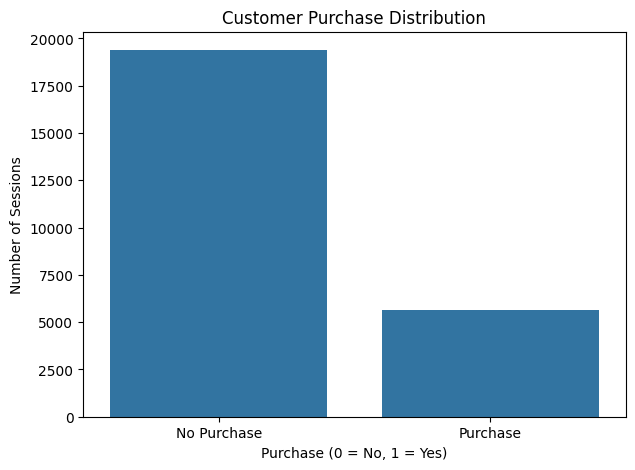

In [ ]:
# Count purchase and non-purchase sessions
purchase_counts = df['purchased'].value_counts().sort_index()

# Plot
plt.figure(figsize=(7, 5))
sns.barplot(
    x=purchase_counts.index,
    y=purchase_counts.values
)

plt.title("Customer Purchase Distribution")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Number of Sessions")
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.show()

Purchase Rate by Device Type:
device_type
2    23.199363
0    22.463841
1    22.317460
Name: purchased, dtype: float64


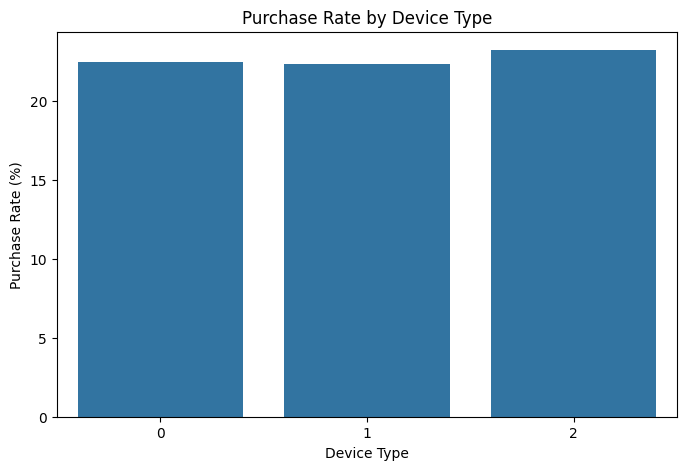

In [ ]:
# Calculate purchase rate for each device type
device_purchase = df.groupby('device_type')['purchased'].mean() * 100

print("Purchase Rate by Device Type:")
print(device_purchase.sort_values(ascending=False))

# Visualize
plt.figure(figsize=(8, 5))
sns.barplot(
    x=device_purchase.index.astype(str),
    y=device_purchase.values
)

plt.title("Purchase Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Purchase Rate (%)")
plt.show()

Purchase Rate by Marketing Channel:
marketing_channel
5    23.598405
0    22.717149
3    22.643343
1    22.124105
2    22.027564
4    21.659771
Name: purchased, dtype: float64


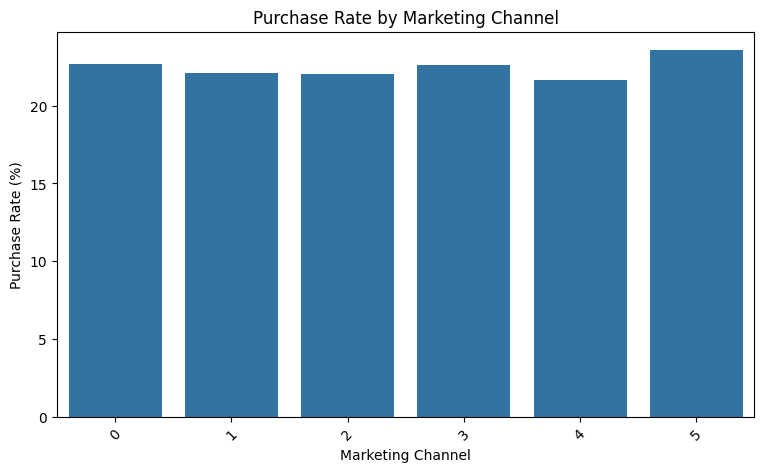

In [ ]:
# Calculate purchase rate by marketing channel
channel_purchase = (
    df.groupby('marketing_channel')['purchased'].mean() * 100
)

print("Purchase Rate by Marketing Channel:")
print(channel_purchase.sort_values(ascending=False))

# Visualize
plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_purchase.index.astype(str),
    y=channel_purchase.values
)

plt.title("Purchase Rate by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Purchase Rate (%)")
plt.xticks(rotation=45)
plt.show()

Purchase Rate by User Type:
user_type
1    25.649398
0    18.550544
Name: purchased, dtype: float64


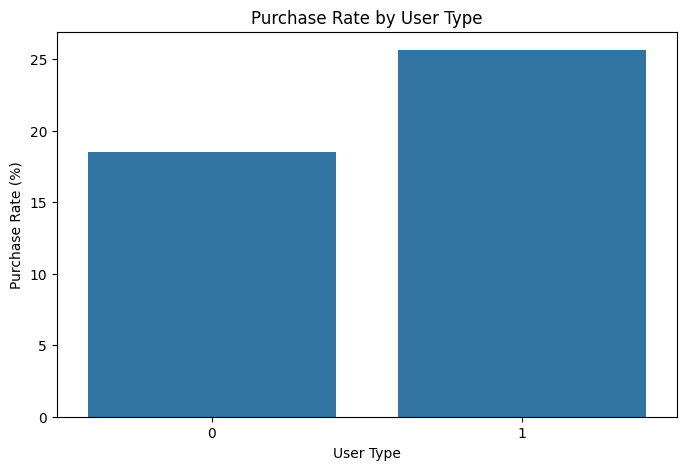

In [ ]:
# Calculate purchase rate by user type
user_purchase = (
    df.groupby('user_type')['purchased'].mean() * 100
)

print("Purchase Rate by User Type:")
print(user_purchase.sort_values(ascending=False))

# Visualize
plt.figure(figsize=(8, 5))

sns.barplot(
    x=user_purchase.index.astype(str),
    y=user_purchase.values
)

plt.title("Purchase Rate by User Type")
plt.xlabel("User Type")
plt.ylabel("Purchase Rate (%)")
plt.show()

Average Time Spent on Website:
purchased
0    895.605809
1    929.691952
Name: time_on_site_sec, dtype: float64


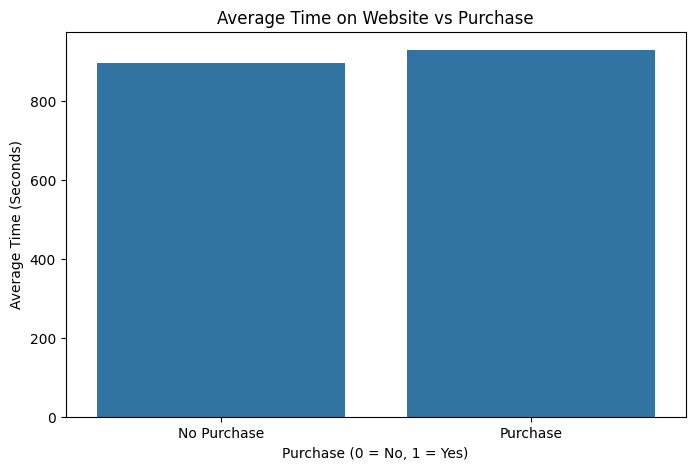

In [ ]:
# Compare average time spent by purchase status
time_analysis = df.groupby('purchased')['time_on_site_sec'].mean()

print("Average Time Spent on Website:")
print(time_analysis)

# Visualize
plt.figure(figsize=(8, 5))

sns.barplot(
    x=time_analysis.index,
    y=time_analysis.values
)

plt.title("Average Time on Website vs Purchase")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Average Time (Seconds)")
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.show()

Average Pages Viewed:
purchased
0    12.512846
1    12.615207
Name: pages_viewed, dtype: float64


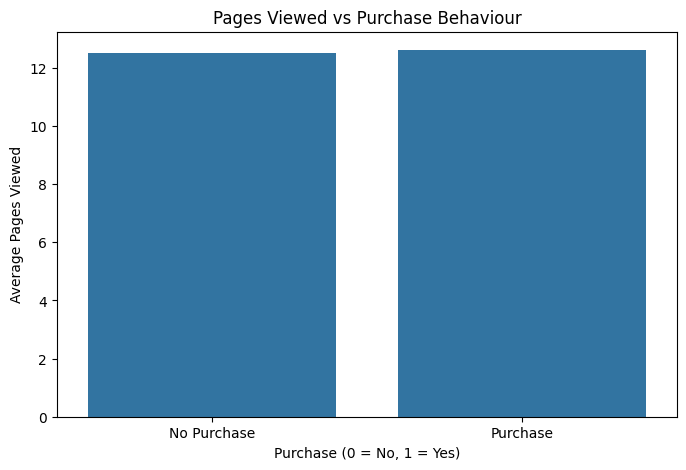

In [ ]:
# Calculate average pages viewed by purchase status
pages_analysis = df.groupby('purchased')['pages_viewed'].mean()

print("Average Pages Viewed:")
print(pages_analysis)

# Visualize
plt.figure(figsize=(8, 5))

sns.barplot(
    x=pages_analysis.index,
    y=pages_analysis.values
)

plt.title("Pages Viewed vs Purchase Behaviour")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Average Pages Viewed")
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.show()

Purchase Rate by Cart Activity:
added_to_cart
0     0.000000
1    34.845195
Name: purchased, dtype: float64


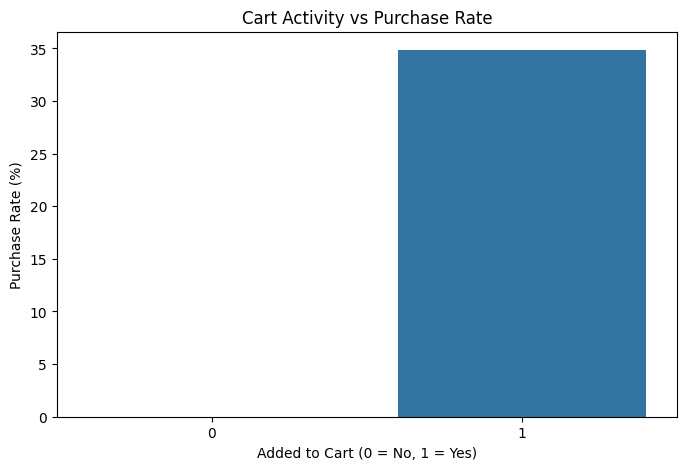

In [ ]:
# Calculate purchase rate based on cart activity
cart_analysis = (
    df.groupby('added_to_cart')['purchased'].mean() * 100
)

print("Purchase Rate by Cart Activity:")
print(cart_analysis)

# Visualize
plt.figure(figsize=(8, 5))

sns.barplot(
    x=cart_analysis.index.astype(str),
    y=cart_analysis.values
)

plt.title("Cart Activity vs Purchase Rate")
plt.xlabel("Added to Cart (0 = No, 1 = Yes)")
plt.ylabel("Purchase Rate (%)")
plt.show()

Average Product Price:
purchased
0    780.122807
1    789.899354
Name: unit_price, dtype: float64


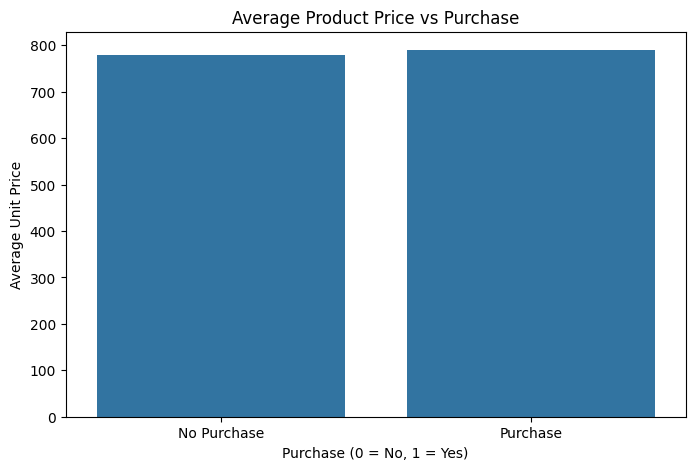

In [ ]:
# Compare average product price by purchase status
price_analysis = df.groupby('purchased')['unit_price'].mean()

print("Average Product Price:")
print(price_analysis)

# Visualize
plt.figure(figsize=(8, 5))

sns.barplot(
    x=price_analysis.index,
    y=price_analysis.values
)

plt.title("Average Product Price vs Purchase")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Average Unit Price")
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.show()

Average Discount Percentage:
purchased
0    8.992210
1    9.021546
Name: discount_percent, dtype: float64


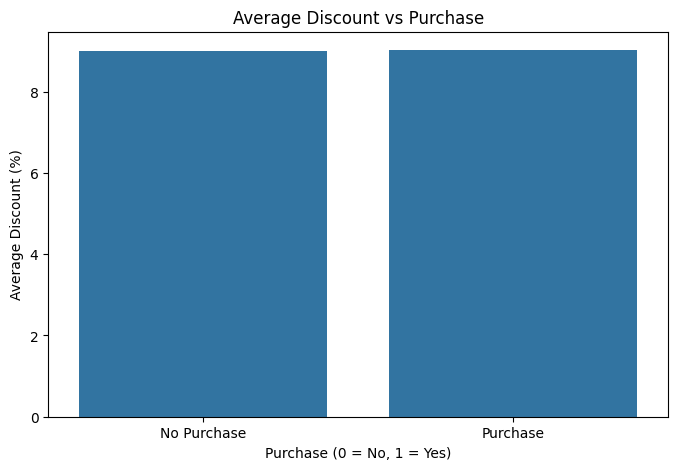

In [ ]:
# Compare average discount percentage by purchase status
discount_analysis = (
    df.groupby('purchased')['discount_percent'].mean()
)

print("Average Discount Percentage:")
print(discount_analysis)

# Visualize
plt.figure(figsize=(8, 5))

sns.barplot(
    x=discount_analysis.index,
    y=discount_analysis.values
)

plt.title("Average Discount vs Purchase")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Average Discount (%)")
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.show()

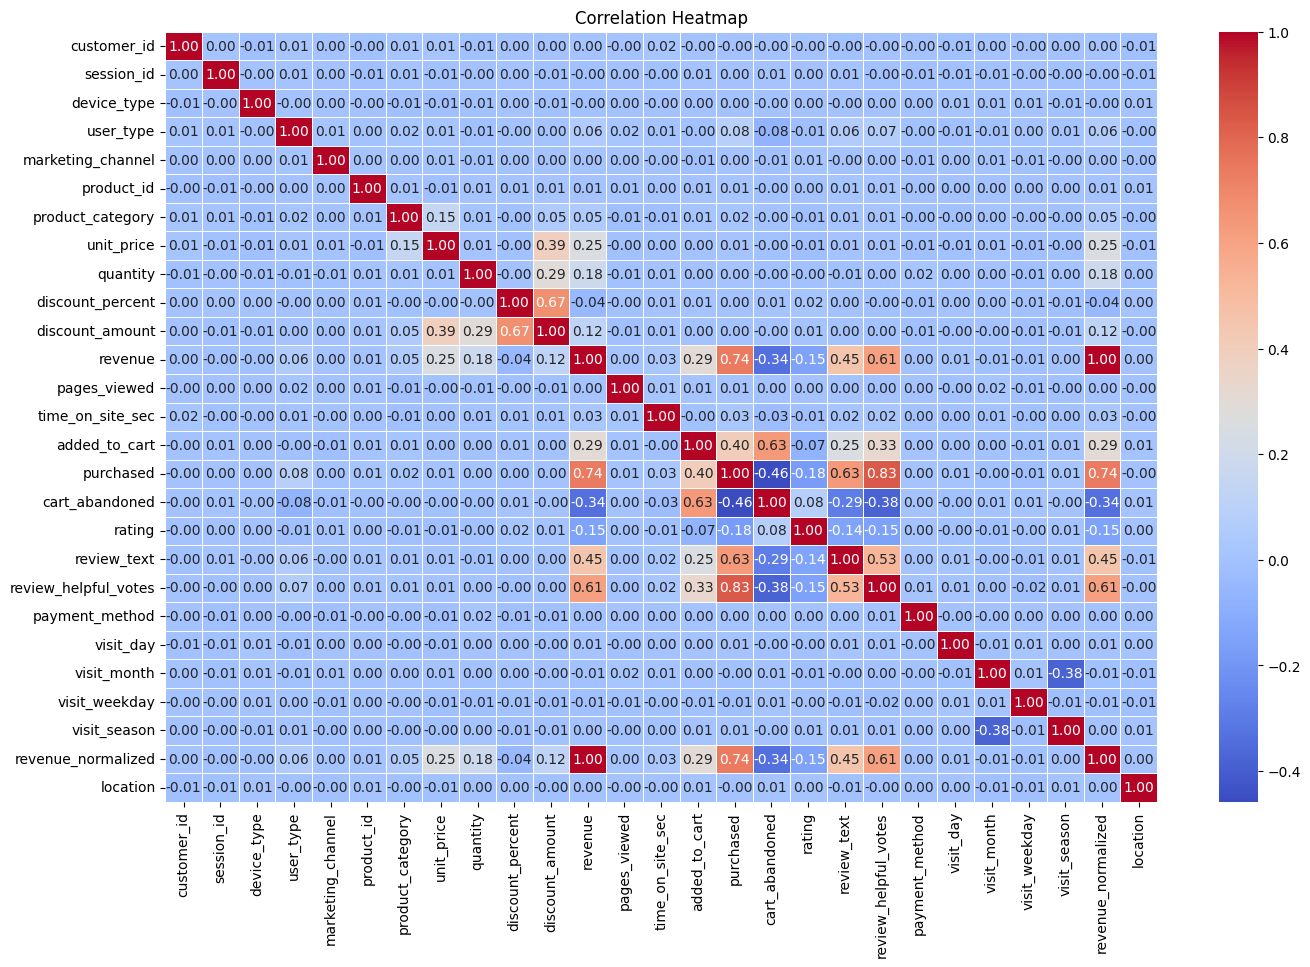

In [ ]:
# Select numerical columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation
correlation = numeric_df.corr()

# Visualize correlation matrix
plt.figure(figsize=(16, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Target variable
target = 'purchased'

# Remove identifiers and columns that can cause data leakage
columns_to_drop = [
    'customer_id',
    'session_id',
    'visit_date',
    'purchased',
    'revenue',
    'discount_amount',
    'revenue_normalized',
    'cart_abandoned',
    'payment_method',
    'rating',
    'review_text',
    'review_helpful_votes'
]

# Create feature dataset
X = df.drop(columns=columns_to_drop)
y = df[target]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature dataset shape: (25000, 17)
Target dataset shape: (25000,)

Selected Features:
['device_type', 'user_type', 'marketing_channel', 'product_id', 'product_category', 'unit_price', 'quantity', 'discount_percent', 'pages_viewed', 'time_on_site_sec', 'added_to_cart', 'visit_day', 'visit_month', 'visit_weekday', 'visit_season', 'session_duration_bucket', 'location']

Target distribution:
purchased
0    19384
1     5616
Name: count, dtype: int64


In [ ]:
# Categorical columns (including numeric-coded categories)
categorical_columns = [
    'device_type',
    'user_type',
    'marketing_channel',
    'product_category',
    'visit_month',
    'visit_weekday',
    'visit_season',
    'session_duration_bucket',
    'location'
]

# Keep only columns that exist in X
categorical_features = [
    col for col in categorical_columns if col in X.columns
]

# Remaining columns are treated as numerical
numerical_features = [
    col for col in X.columns if col not in categorical_features
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nTotal Features:", len(categorical_features) + len(numerical_features))

Categorical Features:
['device_type', 'user_type', 'marketing_channel', 'product_category', 'visit_month', 'visit_weekday', 'visit_season', 'session_duration_bucket', 'location']

Numerical Features:
['product_id', 'unit_price', 'quantity', 'discount_percent', 'pages_viewed', 'time_on_site_sec', 'added_to_cart', 'visit_day']

Total Features: 17


In [ ]:
from sklearn.model_selection import train_test_split

# Split features and target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (20000, 17)
Testing Features: (5000, 17)

Training Target Distribution:
purchased
0    77.535
1    22.465
Name: proportion, dtype: float64

Testing Target Distribution:
purchased
0    77.54
1    22.46
Name: proportion, dtype: float64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for numerical features
numeric_transformer = StandardScaler()

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("Training data shape after preprocessing:", X_train_processed.shape)
print("Testing data shape after preprocessing:", X_test_processed.shape)

Training data shape after preprocessing: (20000, 279)
Testing data shape after preprocessing: (5000, 279)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict on unseen testing data
y_pred_lr = logistic_model.predict(X_test_processed)

# Predict purchase probabilities
y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

print("First 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_lr[:10])

print("\nFirst 10 Purchase Probabilities:")
print(y_prob_lr[:10])

First 10 Actual Values:
[0 1 0 0 0 1 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 0 0 0 0 0 0]

First 10 Purchase Probabilities:
[4.34835032e-04 2.22294798e-01 2.21791755e-04 4.08658561e-04
 3.62689134e-01 4.44153512e-01 3.78083355e-01 3.32743044e-04
 3.11585942e-01 2.59170059e-01]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)
f1 = f1_score(y_test, y_pred_lr)
roc_auc = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation
--------------------------------
Accuracy : 0.7718
Precision: 0.4286
Recall   : 0.0481
F1 Score : 0.0865
ROC-AUC  : 0.7577

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.98      0.87      3877
           1       0.43      0.05      0.09      1123

    accuracy                           0.77      5000
   macro avg       0.60      0.51      0.48      5000
weighted avg       0.70      0.77      0.69      5000



Confusion Matrix:
[[3805   72]
 [1069   54]]


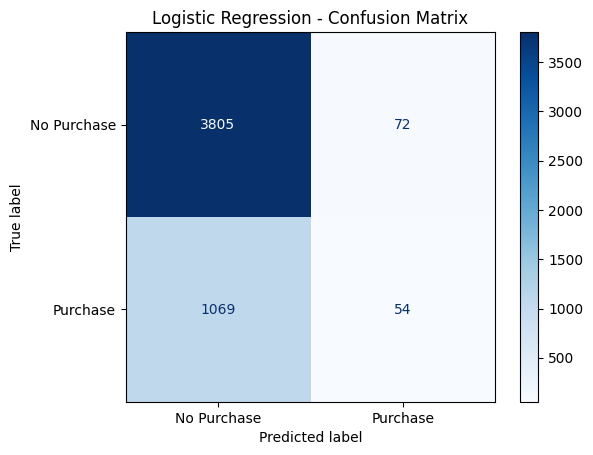

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm)

# Visualize
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Purchase', 'Purchase']
)

display.plot(cmap='Blues', values_format='d')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Predict customer purchases
y_pred_rf = rf_model.predict(X_test_processed)

# Predict purchase probabilities
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

print("First 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Random Forest Predictions:")
print(y_pred_rf[:10])

First 10 Actual Values:
[0 1 0 0 0 1 0 0 0 0]

First 10 Random Forest Predictions:
[0 0 0 0 1 1 1 0 1 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))
print("ROC-AUC  :", round(roc_auc_rf, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Evaluation
------------------------
Accuracy : 0.6248
Precision: 0.3627
Recall   : 0.886
F1 Score : 0.5147
ROC-AUC  : 0.7651

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.55      0.69      3877
           1       0.36      0.89      0.51      1123

    accuracy                           0.62      5000
   macro avg       0.65      0.72      0.60      5000
weighted avg       0.81      0.62      0.65      5000



In [ ]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Logistic Regression': [
        accuracy, precision, recall, f1, roc_auc
    ],
    'Random Forest': [
        accuracy_rf, precision_rf, recall_rf, f1_rf, roc_auc_rf
    ]
})

print(comparison.round(4))

      Metric  Logistic Regression  Random Forest
0   Accuracy               0.7718         0.6248
1  Precision               0.4286         0.3627
2     Recall               0.0481         0.8860
3   F1 Score               0.0865         0.5147
4    ROC-AUC               0.7577         0.7651


In [ ]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance.head(15))

Top 15 Important Features:
                                    Feature  Importance
6                        num__added_to_cart    0.627182
5                     num__time_on_site_sec    0.025521
1                           num__unit_price    0.022992
0                           num__product_id    0.022252
12                         cat__user_type_1    0.019321
11                         cat__user_type_0    0.017841
7                            num__visit_day    0.017077
4                         num__pages_viewed    0.015711
3                     num__discount_percent    0.010195
2                             num__quantity    0.007879
53  cat__session_duration_bucket_Very Short    0.004057
8                        cat__device_type_0    0.003629
25                  cat__product_category_6    0.003480
45                     cat__visit_weekday_6    0.003353
9                        cat__device_type_1    0.003340


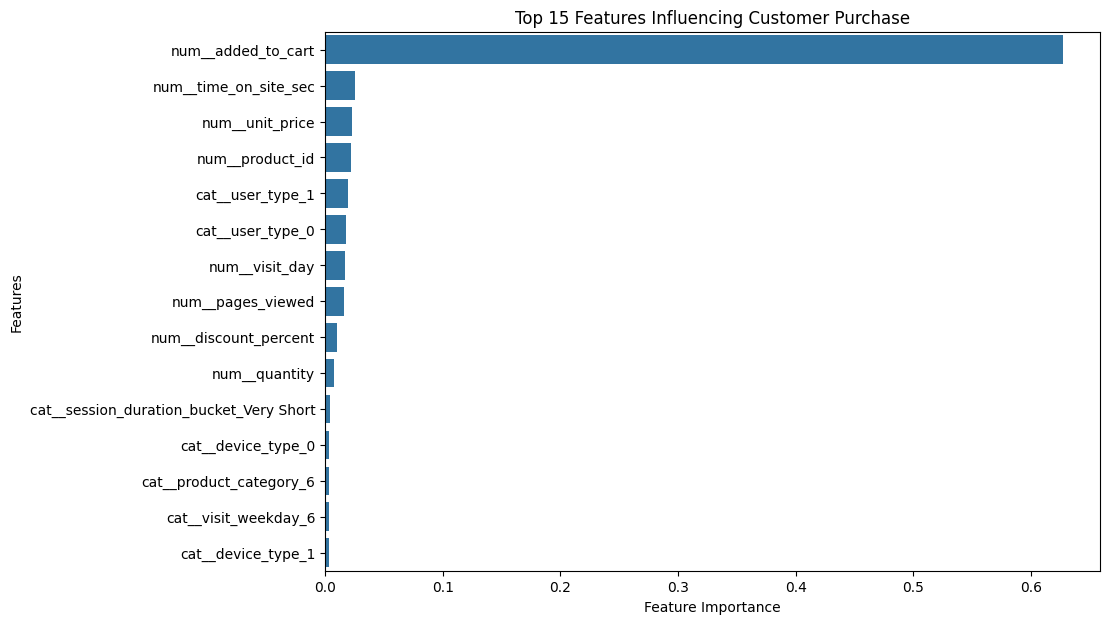

In [ ]:
# Select top 15 features
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Features Influencing Customer Purchase")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.show()

In [ ]:
# Remove added_to_cart from features
X_no_cart = X.drop(columns=['added_to_cart'])

# Split dataset
from sklearn.model_selection import train_test_split

X_train_nc, X_test_nc, y_train_nc, y_test_nc = train_test_split(
    X_no_cart,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify categorical and numerical features
categorical_nc = [
    col for col in categorical_features
    if col in X_no_cart.columns
]

numerical_nc = [
    col for col in X_no_cart.columns
    if col not in categorical_nc
]

# Create preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_nc = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_nc),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_nc)
    ]
)

# Transform training and testing data
X_train_nc_processed = preprocessor_nc.fit_transform(X_train_nc)
X_test_nc_processed = preprocessor_nc.transform(X_test_nc)

# Train Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model_nc = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model_nc.fit(X_train_nc_processed, y_train_nc)

print("Random Forest without added_to_cart trained successfully!")

Random Forest without added_to_cart trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predictions
y_pred_nc = rf_model_nc.predict(X_test_nc_processed)

# Probabilities
y_prob_nc = rf_model_nc.predict_proba(X_test_nc_processed)[:, 1]

# Evaluation
print("Random Forest - Without added_to_cart")
print("--------------------------------------")

print("Accuracy :", round(accuracy_score(y_test_nc, y_pred_nc), 4))
print("Precision:", round(precision_score(y_test_nc, y_pred_nc), 4))
print("Recall   :", round(recall_score(y_test_nc, y_pred_nc), 4))
print("F1 Score :", round(f1_score(y_test_nc, y_pred_nc), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_nc, y_prob_nc), 4))

Random Forest - Without added_to_cart
--------------------------------------
Accuracy : 0.5874
Precision: 0.2614
Recall   : 0.4586
F1 Score : 0.333
ROC-AUC  : 0.5608


In [ ]:
comparison_rf = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],

    'With Cart Activity': [
        accuracy_rf,
        precision_rf,
        recall_rf,
        f1_rf,
        roc_auc_rf
    ],

    'Without Cart Activity': [
        accuracy_score(y_test_nc, y_pred_nc),
        precision_score(y_test_nc, y_pred_nc),
        recall_score(y_test_nc, y_pred_nc),
        f1_score(y_test_nc, y_pred_nc),
        roc_auc_score(y_test_nc, y_prob_nc)
    ]
})

print(comparison_rf.round(4))

      Metric  With Cart Activity  Without Cart Activity
0   Accuracy              0.6248                 0.5874
1  Precision              0.3627                 0.2614
2     Recall              0.8860                 0.4586
3   F1 Score              0.5147                 0.3330
4    ROC-AUC              0.7651                 0.5608


In [ ]:
final_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression (With Cart)',
        'Random Forest (With Cart)',
        'Random Forest (Without Cart)'
    ],

    'Accuracy': [
        accuracy,
        accuracy_rf,
        accuracy_score(y_test_nc, y_pred_nc)
    ],

    'Precision': [
        precision,
        precision_rf,
        precision_score(y_test_nc, y_pred_nc)
    ],

    'Recall': [
        recall,
        recall_rf,
        recall_score(y_test_nc, y_pred_nc)
    ],

    'F1 Score': [
        f1,
        f1_rf,
        f1_score(y_test_nc, y_pred_nc)
    ],

    'ROC-AUC': [
        roc_auc,
        roc_auc_rf,
        roc_auc_score(y_test_nc, y_prob_nc)
    ]
})

print(final_comparison.round(4))

                             Model  Accuracy  Precision  Recall  F1 Score  \
0  Logistic Regression (With Cart)    0.7718     0.4286  0.0481    0.0865   
1        Random Forest (With Cart)    0.6248     0.3627  0.8860    0.5147   
2     Random Forest (Without Cart)    0.5874     0.2614  0.4586    0.3330   

   ROC-AUC  
0   0.7577  
1   0.7651  
2   0.5608  


In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

# Treat product_id as a categorical feature
categorical_xgb = categorical_nc + ['product_id']
numerical_xgb = [
    col for col in X_no_cart.columns
    if col not in categorical_xgb
]

# Preprocessing
preprocessor_xgb = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_xgb),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_xgb)
    ]
)

# Transform data
X_train_xgb = preprocessor_xgb.fit_transform(X_train_nc)
X_test_xgb = preprocessor_xgb.transform(X_test_nc)

# Calculate class imbalance ratio
scale_weight = (
    (y_train_nc == 0).sum() /
    (y_train_nc == 1).sum()
)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train_xgb, y_train_nc)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [ ]:
# Predictions
y_pred_xgb = xgb_model.predict(X_test_xgb)

# Purchase probabilities
y_prob_xgb = xgb_model.predict_proba(X_test_xgb)[:, 1]

# Evaluation
print("XGBoost Evaluation")
print("------------------")

print("Accuracy :", round(accuracy_score(y_test_nc, y_pred_xgb), 4))
print("Precision:", round(precision_score(y_test_nc, y_pred_xgb), 4))
print("Recall   :", round(recall_score(y_test_nc, y_pred_xgb), 4))
print("F1 Score :", round(f1_score(y_test_nc, y_pred_xgb), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_nc, y_prob_xgb), 4))

XGBoost Evaluation
------------------
Accuracy : 0.5384
Precision: 0.2557
Recall   : 0.5521
F1 Score : 0.3495
ROC-AUC  : 0.5577


In [ ]:
xgb_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],

    'Random Forest': [
        accuracy_score(y_test_nc, y_pred_nc),
        precision_score(y_test_nc, y_pred_nc),
        recall_score(y_test_nc, y_pred_nc),
        f1_score(y_test_nc, y_pred_nc),
        roc_auc_score(y_test_nc, y_prob_nc)
    ],

    'XGBoost': [
        accuracy_score(y_test_nc, y_pred_xgb),
        precision_score(y_test_nc, y_pred_xgb),
        recall_score(y_test_nc, y_pred_xgb),
        f1_score(y_test_nc, y_pred_xgb),
        roc_auc_score(y_test_nc, y_prob_xgb)
    ]
})

print(xgb_comparison.round(4))

      Metric  Random Forest  XGBoost
0   Accuracy         0.5874   0.5384
1  Precision         0.2614   0.2557
2     Recall         0.4586   0.5521
3   F1 Score         0.3330   0.3495
4    ROC-AUC         0.5608   0.5577


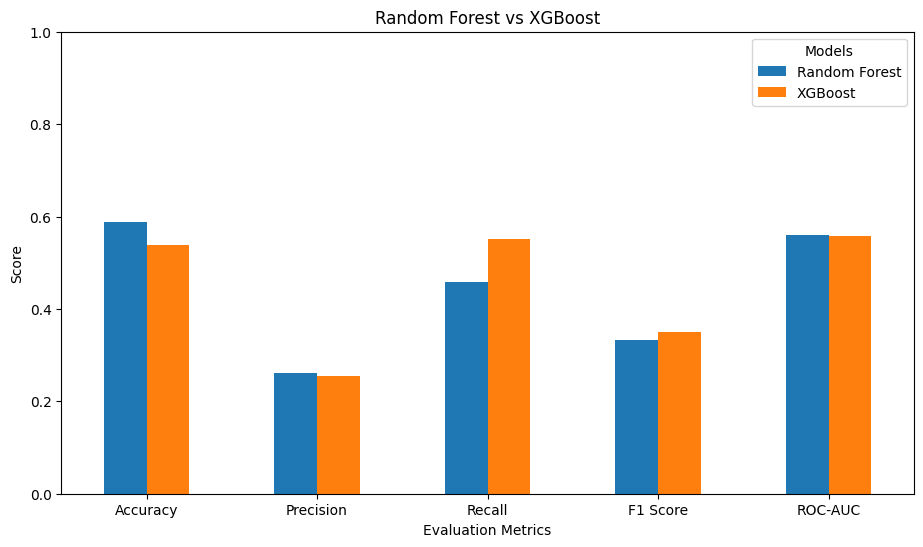

In [ ]:
comparison_plot = xgb_comparison.set_index('Metric')

comparison_plot.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title("Random Forest vs XGBoost")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Models")
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

# Base model
xgb_base = XGBClassifier(
    scale_pos_weight=scale_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Parameters to test
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.03, 0.05, 0.1]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    n_jobs=-1
)

# Train and search
grid_search.fit(X_train_xgb, y_train_nc)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters:
{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100}

Best Cross-Validation ROC-AUC:
0.5562


In [ ]:
# Get best model
best_xgb_model = grid_search.best_estimator_

# Predictions
y_pred_tuned = best_xgb_model.predict(X_test_xgb)
y_prob_tuned = best_xgb_model.predict_proba(X_test_xgb)[:, 1]

# Evaluation
print("Tuned XGBoost Evaluation")
print("------------------------")

print("Accuracy :", round(accuracy_score(y_test_nc, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test_nc, y_pred_tuned), 4))
print("Recall   :", round(recall_score(y_test_nc, y_pred_tuned), 4))
print("F1 Score :", round(f1_score(y_test_nc, y_pred_tuned), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test_nc, y_prob_tuned), 4))

Tuned XGBoost Evaluation
------------------------
Accuracy : 0.5102
Precision: 0.2552
Recall   : 0.6153
F1 Score : 0.3607
ROC-AUC  : 0.5648


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    predictions = (y_prob_tuned >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_test_nc, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test_nc, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test_nc, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   Threshold  Precision  Recall  F1 Score
0        0.3     0.2245  0.9991    0.3667
1        0.4     0.2273  0.9742    0.3685
2        0.5     0.2552  0.6153    0.3607
3        0.6     0.0000  0.0000    0.0000
4        0.7     0.0000  0.0000    0.0000


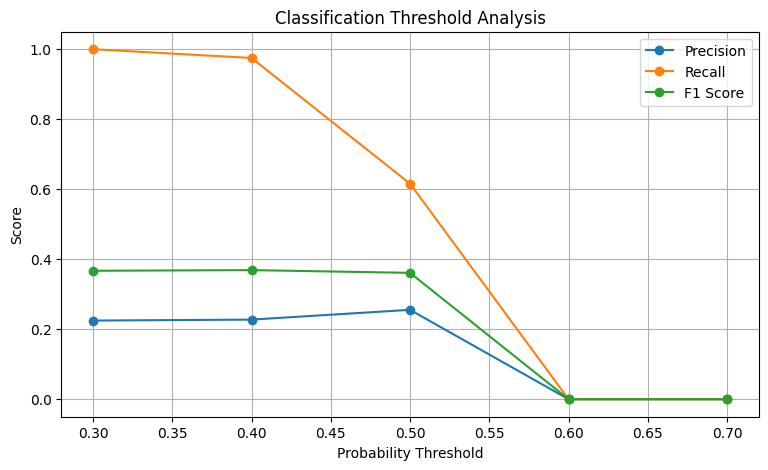

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.title("Classification Threshold Analysis")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

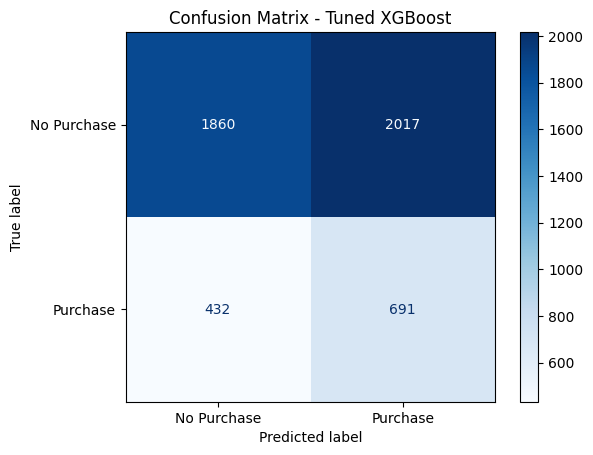

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict using threshold 0.50
y_pred_final = (y_prob_tuned >= 0.50).astype(int)

# Create confusion matrix
cm = confusion_matrix(y_test_nc, y_pred_final)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Purchase', 'Purchase']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Tuned XGBoost")
plt.show()

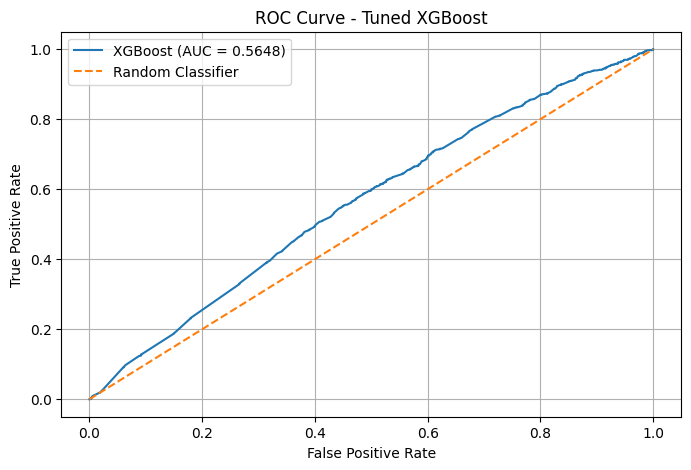

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve
fpr, tpr, thresholds_roc = roc_curve(y_test_nc, y_prob_tuned)

# Calculate AUC
auc_score = roc_auc_score(y_test_nc, y_prob_tuned)

# Plot ROC curve
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned XGBoost')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import joblib
import os

# Create models folder
os.makedirs('/content/models', exist_ok=True)

# Save trained model
joblib.dump(
    best_xgb_model,
    '/content/models/customer_purchase_xgboost.joblib'
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor_xgb,
    '/content/models/customer_purchase_preprocessor.joblib'
)

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!
